In [2]:
import sys
sys.path[:0] = ['..']   # this repository: the extant package and plotting_modules

import logging
import warnings
from functools import partial
from importlib import reload

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np
import pandas as pd
from numba import njit
import xarray as xr

from dask.distributed import wait
# from plotting_modules import formatting
# from plotting_modules.constants import FORCING_COLORS
from extant import config, datatree, loading, paths, preprocessing as pp, storage, zonal
# from extant import quantiles as qc, response_change as rc, significance as sig
# from extant import observed_change as oc, probability_ratio as pr, sam
from extant.logger import setup_logging
# from extant.plots import methods
# from extant.plots import zonal as zp
# from extant.stats import nan_quantile

logger = setup_logging('extant', logging.INFO)
xr.set_options(display_expand_attrs=False, display_expand_data=False)

#(t): Dask warns about every large task graph; the graphs here are large on purpose
warnings.filterwarnings('ignore', message='.*Sending large graph of size.*', category=UserWarning)

In [3]:
#(t): Start a Dask Gateway cluster, or reuse the one already running, and send it the extant package
#(c): Re-run upload_package after editing anything in extant/: the workers run its functions
from extant import jasmin

gateway, cluster, client = jasmin.connect(n_workers=20, wait_for=6)
jasmin.upload_package(client)
client

Connection method: Cluster object,Cluster type: dask_gateway.GatewayCluster
Dashboard: /_jasmin/proxy/dask-gateway/clusters/66d6ae4aee954587bf0e9a28831c81e7/status,


In [4]:
VARIABLE = 'tas'

In [5]:
#(t): The two places the seasonal store can be: DATA_DIR is read first, then SCRATCH
seasonal_store = paths.seasonal('lesfmip', VARIABLE)
pd.Series({str(root / seasonal_store): (root / seasonal_store).exists() for root in (paths.DATA_DIR, paths.SCRATCH)},
          name='exists')

/gws/ssde/j25b/leader_epesc/aborow/ExtAnt/seasonal/lesfmip_tas.zarr    False
/work/scratch-pw4/aborow/ExtAnt/seasonal/lesfmip_tas.zarr               True
Name: exists, dtype: bool

In [6]:
seasonal_path = paths.find(seasonal_store)
seasonal_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/seasonal/lesfmip_tas.zarr')

In [7]:
lesfmip_season_tree = xr.open_datatree(seasonal_path, engine='zarr', chunks={})


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be suppor

In [8]:
lesfmip_season_tree

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-GHG
│   │       Dimensions:  (member: 50, lat: 20, lon: 144, year: 164, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float32 378MB dask.array<chunksize=(50, 4, 144, 164, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-aer
│   │       Dimensions:  (member: 30, lat: 20, lon: 144, year: 164, season: 4)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 240B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float32 227MB dask.array<chunksize=(30, 4, 144, 164, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:  (member: 50, lat: 20, lon: 144, year: 164, season: 4)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float32 378MB dask.array<chunksize=(50, 4, 144, 164, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-totalO3
│   │       Dimensions:  (member: 10, lat: 20, lon: 144, year: 164, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * member   (member) object 80B 'r10i1p1f1' 'r1i1p1f1' ... 'r9i1p1f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float32 76MB dask.array<chunksize=(10, 4, 144, 164, 4), meta=np.ndarray>
│   └── Group: /CanESM5/historical
│           Dimensions:  (member: 65, lat: 20, lon: 144, year: 164, season: 4)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│             * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│           Data variables:
│               tas      (member, lat, lon, year, season) float32 491MB dask.array<chunksize=(65, 4, 144, 164, 4), meta=np.ndarray>
├── Group: /GISS-E2-1-G
│   ├── Group: /GISS-E2-1-G/hist-GHG
│   │       Dimensions:  (member: 45, lat: 20, lon: 144, year: 164, season: 4)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0

# Calculations

In [9]:
@njit(cache=True)
def rolling_member_mean(arr, window=21):
    n_members, n_years = arr.shape
    n_repeats = n_years - window + 1
    n_points = n_members * window
    out_values = np.empty(n_repeats)

    rolling_val = np.sum(arr[:, :window])

    for i in range(n_repeats):
        if i > 0:
            rolling_val -= np.sum(arr[:, i-1])
            rolling_val += np.sum(arr[:, i+window-1])

        out_values[i] = rolling_val / n_points

    return out_values

In [10]:
def member_mapblocks(ds):
    window = 21

    njit_member_mean = xr.apply_ufunc(
        rolling_member_mean,
        ds,
        input_core_dims=[['member', 'year']],
        output_core_dims=[['year2']],
        vectorize=True,
        dask='parallelized',
        output_dtypes=[float],
        dask_gufunc_kwargs={"output_sizes": {"year2": ds.sizes['year'] - window + 1}},
    )

    njit_member_mean = njit_member_mean.assign_coords(
        year2=ds['year'].isel(year=slice(window // 2, -(window // 2))).values
    ).rename({'year2': 'year'})

    return njit_member_mean

In [11]:
sample_da = lesfmip_season_tree['CanESM5']['hist-nat'].tas

In [12]:
base_climatology = sample_da.mean(dim=['year', 'member']).compute()

(array([ 215.,  613.,  665.,  963., 1244., 1043., 1085., 2356., 2869.,
         467.]),
 array([-68.77153015, -59.75523758, -50.73894501, -41.72265625,
        -32.70636368, -23.69007111, -14.67378235,  -5.65748978,
          3.3588028 ,  12.37509155,  21.39138985]),
 <BarContainer object of 10 artists>)

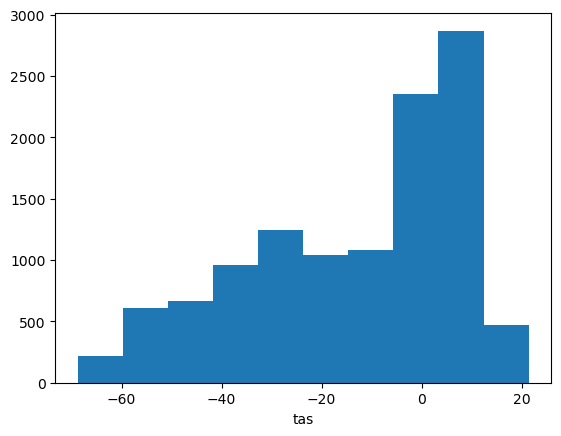

In [13]:
base_climatology.plot()

In [14]:
rolling_da = sample_da.rolling(year=21, center=True, min_periods=21).construct('window')

In [15]:
rolling_da

<xarray.DataArray 'tas' (member: 50, lat: 20, lon: 144, year: 164, season: 4,
                         window: 21)> Size: 8GB
dask.array<chunksize=(17, 2, 48, 163, 2, 21), meta=np.ndarray>
Coordinates:
  * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
  * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
Dimensions without coordinates: window

In [16]:
rolling_da_base = rolling_da.mean(dim=['member', 'window']).compute()

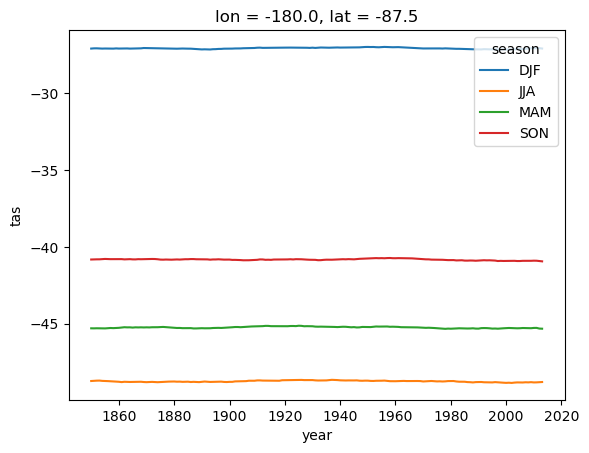

In [17]:
rolling_da_base.isel(lat=0, lon=0).plot(hue='season');

In [18]:
N_TRIALS = 1000
n_members = 10

In [19]:
ensemble_combinations = np.random.choice(sample_da.sizes['member'], size=(N_TRIALS, n_members), replace=True)

In [20]:
ensemble_combinations.shape

(1000, 10)

In [21]:
idx_da = xr.DataArray(ensemble_combinations, dims=('trial', 'member'))

In [22]:
idx_da

<xarray.DataArray (trial: 1000, member: 10)> Size: 80kB
49 41 23 45 24 46 31 22 20 5 47 7 25 11 ... 24 10 3 7 44 10 21 13 39 7 47 22 1
Dimensions without coordinates: trial, member

In [23]:
sample_arr = sample_da.isel(lat=0, lon=0, season=0).values
sample_arr.shape

(50, 164)

In [24]:
test_roll = rolling_member_mean(sample_arr)
test_roll.shape

(144,)

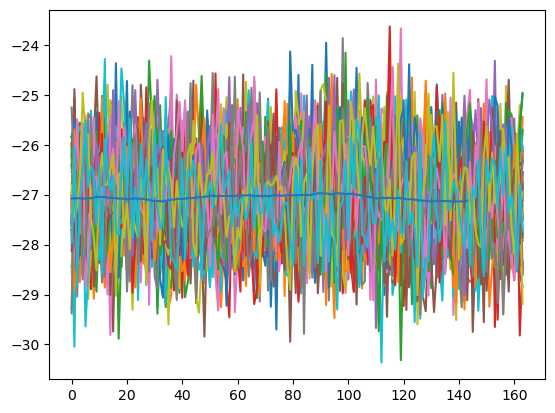

In [25]:
plt.plot(sample_arr.T)
plt.plot(test_roll)

In [26]:
sample_da_idx = sample_da.isel(member=idx_da).chunk({'trial':100, 'member':-1, 'lat':5, 'lon':-1, 'year':-1})

In [27]:
sample_da_idx

<xarray.DataArray 'tas' (trial: 1000, member: 10, lat: 20, lon: 144, year: 164,
                         season: 4)> Size: 76GB
dask.array<chunksize=(100, 10, 5, 144, 164, 4), meta=np.ndarray>
Coordinates:
  * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
    member   (trial, member) object 80kB dask.array<chunksize=(100, 10), meta=np.ndarray>
Dimensions without coordinates: trial

In [ ]:
%%time
# (c): Times with 500 trails and 10 members
# (c): no numba, no cache: 1min 6s
# (c)  numba, no cache: 11.2s, 21.5
# (c)  numba, cache: 10.9s, 11.3, 
rolling_da_bootstrap_anom = member_mapblocks(sample_da_idx)
rolling_da_bootstrap_anom = rolling_da_bootstrap_anom.compute()

In [ ]:
rolling_da_bootstrap_anom

In [ ]:
rolling_da_base

In [ ]:
# Converting to anomalies
rolling_da_bootstrap_anom = rolling_da_bootstrap_anom - rolling_da_base.isel(year=slice(10, -10))

In [ ]:
# This the uncertainty across all trials and all years
uncertainty_da = rolling_da_bootstrap_anom.std(dim=['trial', 'year'])

In [ ]:
rolling_da_bootstrap_anom.isel(lat=0, lon=0).isel(year=slice(11, None)).plot(hue='trial', add_legend=False);

In [ ]:
uncertainty_da.plot(
    robust=True,
    subplot_kws=dict(projection=ccrs.SouthPolarStereo()), transform=ccrs.PlateCarree())

In [ ]:
# Turn this into a function

N_TRIALS = 250

uncertainty_stor = []
for n_members in [5, 10, 20, 25, 30, 40, 50]:
    ensemble_combinations = np.random.choice(
        sample_da.sizes['member'], size=(N_TRIALS, n_members), replace=True)
    idx_da = xr.DataArray(ensemble_combinations, dims=('trial', 'member'))
    sample_da_idx = (sample_da.isel(member=idx_da)
        .chunk({'trial':100, 'member':-1, 'lat':5, 'lon':-1, 'year':-1}))
    rolling_da_bootstrap_anom = member_mapblocks(sample_da_idx)
    rolling_da_bootstrap_anom = rolling_da_bootstrap_anom.compute()
    rolling_da_bootstrap_anom = rolling_da_bootstrap_anom - rolling_da_base.isel(year=slice(10, -10))
    uncertainty_da = rolling_da_bootstrap_anom.std(dim=['trial', 'year'])
    uncertainty_da = uncertainty_da.expand_dims(n_members=[n_members])

    uncertainty_stor.append(uncertainty_da)

In [ ]:
uncertainty_ds = xr.concat(uncertainty_stor, dim='n_members')

In [ ]:
uncertainty_ds

In [ ]:
# Cell that applies to all-hist nat

## Plots

In [ ]:
from extant.plots import forced_response as fr

In [ ]:
fr.map_grid

In [ ]:
miliniski_scale = fr.Scale(levels=np.arange(0, 0.45, 0.05))

In [ ]:
panels = fr.map_grid(uncertainty_ds, miliniski_scale, title=f'',
                     row_dim='n_members', col_dim='season')

In [ ]:
uncertainty_ds.plot(
    col='n_members', col_wrap=3, robust=True,
    # subplot_kws=dict(projection=ccrs.SouthPolarStereo()), transform=ccrs.PlateCarree()
)